In [1]:
# Core scientific Python and scikit-learn libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone
import joblib
import sklearn

RANDOM_STATE = 42
print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.6.1


In [2]:

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
display(df.head())
display(df.describe().round(3))

Shape: (20640, 9)
Missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000
mean,3.871,28.639,5.429,1.097,1425.477,3.071,35.632,-119.570,2.069
std,1.900,12.586,2.474,0.474,1132.462,10.386,2.136,2.004,1.154
min,0.500,1.000,0.846,0.333,3.000,0.692,32.540,-124.350,0.150
25%,2.563,18.000,4.441,1.006,787.000,2.430,33.930,-121.800,1.196
50%,3.535,29.000,5.229,1.049,1166.000,2.818,34.260,-118.490,1.797
75%,4.743,37.000,6.052,1.100,1725.000,3.282,37.710,-118.010,2.647
max,15.000,52.000,141.909,34.067,35682.000,1243.333,41.950,-114.310,5.000


## Exploratory analysis

MedHouseVal    1.000
MedInc         0.688
AveRooms       0.152
HouseAge       0.106
AveOccup      -0.024
Population    -0.025
Longitude     -0.046
AveBedrms     -0.047
Latitude      -0.144
Name: MedHouseVal, dtype: float64


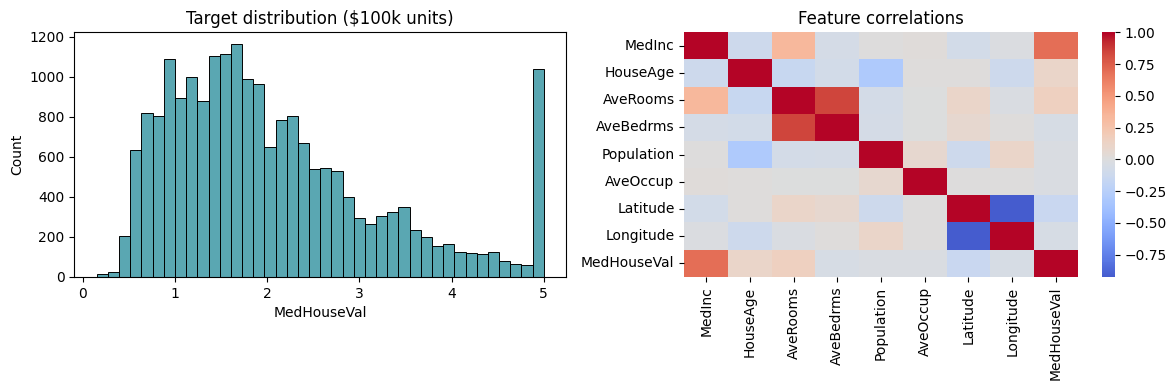

In [3]:
# Feature-to-target correlations and the target distribution
correlations = df.corr(numeric_only=True)['MedHouseVal'].sort_values(ascending=False)
print(correlations.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['MedHouseVal'], bins=40, ax=axes[0], color='#238a98')
axes[0].set_title('Target distribution ($100k units)')
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Feature correlations')
plt.tight_layout()
plt.show()

## Train/test split **before** preprocessing


In [4]:
X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f'Train: {len(X_train):,} | Test: {len(X_test):,}')

Train: 16,512 | Test: 4,128


## Compare three models
`StandardScaler` is used for the linear models, and is fitted **only on training data**. Scaling is not required by a decision tree. Each model receives the same train/test split.

- **Linear Regression:** unregularized baseline.
- **Ridge Regression:** L2-regularized linear model with `alpha=1.0`.
- **Decision Tree:** nonlinear model with `max_depth=5`, as in the assignment.

In [5]:
linear_preprocessing = [
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
]

models = {
    'Linear Regression': Pipeline(linear_preprocessing + [('model', LinearRegression())]),
    'Ridge Regression': Pipeline(linear_preprocessing + [('model', Ridge(alpha=1.0))]),
    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))
    ]),
}

records, fitted_models, test_predictions = [], {}, {}
for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    fitted_models[name] = estimator
    pred_train = estimator.predict(X_train)
    pred_test = estimator.predict(X_test)
    test_predictions[name] = pred_test
    records.append({
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, pred_train)),
        'Test MAE': mean_absolute_error(y_test, pred_test),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, pred_test)),
        'Train R2': r2_score(y_train, pred_train),
        'Test R2': r2_score(y_test, pred_test),
    })
results_df = pd.DataFrame(records).sort_values('Test RMSE').reset_index(drop=True)
display(results_df.round(4))
print('Note: Errors in $100k units. Multiply by $100,000 to obtain approximate USD amounts.')

,Model,Train RMSE,Test MAE,Test RMSE,Train R2,Test R2
0,Decision Tree,0.6959,0.5223,0.7242,0.6377,0.5997
1,Ridge Regression,0.7197,0.5332,0.7456,0.6126,0.5758
2,Linear Regression,0.7197,0.5332,0.7456,0.6126,0.5758


Note: Errors in $100k units. Multiply by $100,000 to obtain approximate USD amounts.


## Visual performance comparison and model diagnostics
Lower test RMSE and MAE are better; higher test R² is better. A large gap between train and test performance can indicate overfitting.

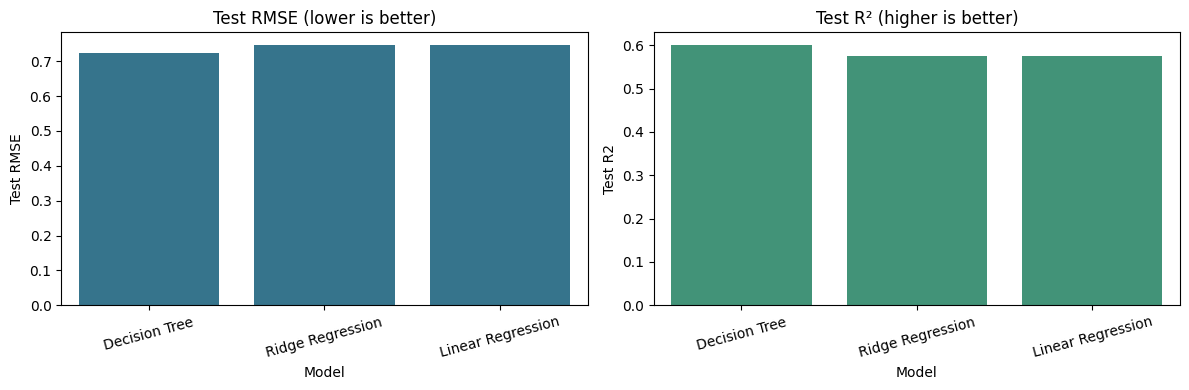

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=results_df, x='Model', y='Test RMSE', ax=axes[0], color='#287a9a')
sns.barplot(data=results_df, x='Model', y='Test R2', ax=axes[1], color='#35a07c')
for ax in axes:
    ax.tick_params(axis='x', rotation=15)
axes[0].set_title('Test RMSE (lower is better)')
axes[1].set_title('Test R² (higher is better)')
plt.tight_layout()
plt.savefig('task2_model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

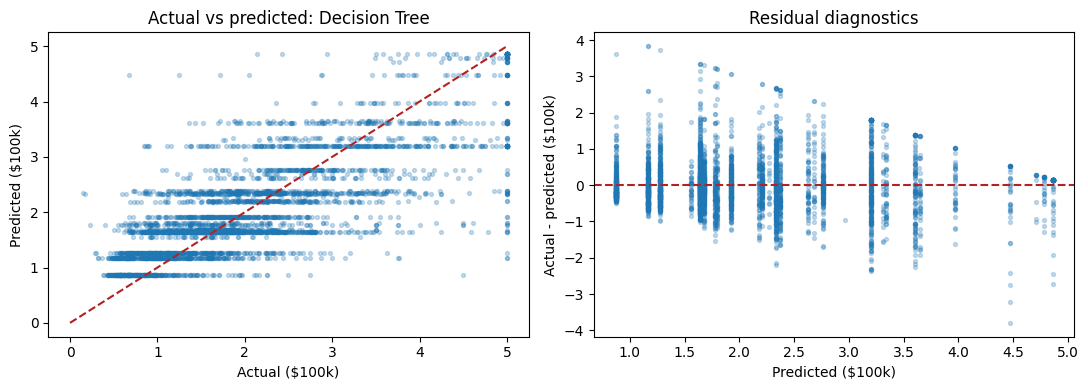

Best of the three specified models (by test RMSE): Decision Tree


In [7]:
# Automatically select the model with the lowest test RMSE.
best_name = results_df.iloc[0]['Model']
best_model = fitted_models[best_name]
best_pred = test_predictions[best_name]
residuals = y_test.to_numpy() - best_pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, best_pred, s=8, alpha=0.25)
limit = max(float(y_test.max()), float(np.max(best_pred)))
axes[0].plot([0, limit], [0, limit], '--', color='firebrick')
axes[0].set(xlabel='Actual ($100k)', ylabel='Predicted ($100k)', title=f'Actual vs predicted: {best_name}')
axes[1].scatter(best_pred, residuals, s=8, alpha=0.25)
axes[1].axhline(0, ls='--', color='firebrick')
axes[1].set(xlabel='Predicted ($100k)', ylabel='Actual - predicted ($100k)', title='Residual diagnostics')
plt.tight_layout()
plt.savefig('task2_best_model_diagnostics.png', dpi=180, bbox_inches='tight')
plt.show()
print('Best of the three specified models (by test RMSE):', best_name)

In [8]:
# Optional: cross-validated hyperparameter optimization.
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search_spaces = {
    'Tuned Ridge': (
        Pipeline(linear_preprocessing + [('model', Ridge())]),
        {'model__alpha': [0.1, 1, 10, 100, 1000]},
    ),
    'Tuned Decision Tree': (
        Pipeline([('imputer', SimpleImputer(strategy='median')),
                  ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))]),
        {'model__max_depth': [3, 5, 8, 12], 'model__min_samples_leaf': [1, 5, 15]},
    ),
}
tuning_rows = []
tuned_models = {}
for name, (estimator, grid) in search_spaces.items():
    search = GridSearchCV(estimator, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    p = search.predict(X_test)
    tuning_rows.append({'Model': name, 'CV RMSE': -search.best_score_,
                        'Test RMSE': np.sqrt(mean_squared_error(y_test, p)),
                        'Test R2': r2_score(y_test, p),
                        'Best parameters': str(search.best_params_)})
tuning_df = pd.DataFrame(tuning_rows).sort_values('CV RMSE')
display(tuning_df)

,Model,CV RMSE,Test RMSE,Test R2,Best parameters
1,Tuned Decision Tree,0.614905,0.602180,0.723277,"{'model__max_depth': 12, 'model__min_samples_l..."
0,Tuned Ridge,0.720509,0.745557,0.575816,{'model__alpha': 1}


In [9]:
# Save the strongest tuned model by cross-validation score.
selected_name = tuning_df.iloc[0]['Model']
selected_model = tuned_models[selected_name]
joblib.dump(selected_model, 'task2_best_model.joblib')
print('Saved task2_best_model.joblib | Selected from training CV:', selected_name)
print('Create a 1–2 page PDF using the metrics and figures above after running all cells.')

Saved task2_best_model.joblib | Selected from training CV: Tuned Decision Tree
Create a 1–2 page PDF using the metrics and figures above after running all cells.
